# Region Segmenation

In this tutorial we will break down the void space in a material into segmented pockets centered around the local maxima. Hence, the key steps in the tutorial are:
- Compute the distance grid 
- Detect the local maxima in the distance grid
- Decide a mask thickness, to distinguish between the void space and the material
- Segment the void space into regions
- The key parameters that you can tune
- Visualize the segmentation results 

We have already seen how to compute the distance grid in the [Distance grid notebook](docs/distance_grid.ipynb). If that seems unclear, please go through that tutorial first. We will quickly go through the steps up until the calculation of the distance grid.

## Imports and paths

In [1]:
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)

import mofography as mgr

path_to_cif = os.path.join(path_to_mgr, 'examples',
                           'TestCIFs', 'P1-IRMOF-1.cif')


## Read the material structure

Read in the CIF file use ASE into an ASE atoms object.

In [2]:
from ase.io import read 
mat_atoms = read(path_to_cif)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\io\cif.py:401: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Compute the distance grid

Let's compute a distance grid, as we've seen before. We are using a pretty coarse grid spacing of 0.5 $\AA$ here, but you can use a finer grid if you'd prefer that.

In [3]:
dgrid = mgr.dgrid_from_atoms(mat_updated, spacing=0.5)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)
Computing distance grid: 100%|██████████| 3/3 [00:00<00:00,  3.60it/s]


## Watershed segmentation

Under the hood, mofography uses 'Watershed segmentation' as implemented in Scikit-Image, to segment the void space into regions. The idea is to use the distance grid to find the local maxima, and then use the watershed algorithm to segment the void space into regions. The watershed algorithm is a pretty powerful tool, and you can read more about it [here](https://scikit-image.org/docs/dev/auto_examples/segmentation/plot_watershed.html).


Note that we are working with 3D instead of a 2D image here. The result of watershed segmentation is another 3D grid, where the value at each voxel represents the region number to which the voxel belongs to. The region number of zero is reserved for the background. 
*mask_thickenss*:Essentially, by setting a value here we say that all the voxels within a certain `mask_thickness` of the framework surface are part of the material, and the rest are part of the void space. We do not want to create fictitious holes in the material, like for example, through the metallic nodes in a MOFs or through the center of an cyclic aliphatic or aromatic ring. Hence, a `mask_thickness` of 1.5 $\AA$ is a good choice for a lot of the cases.

Let's do some region segmenation

In [4]:
regions, maxima= mgr.regions_from_dgrid(dgrid.compute(), mask_thickness=1.5)

c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\compute.py:446: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')


## Tunable parameters

As mentioned earlier, there are 2 steps withing the `regions_from_dgrid' routine in mofography,
- Computing the local maxima
- Computing the region segmentation.

    *h parameter*:
    mofography uses the `h_maxima` function from Scikit-Image to compute the local maxima. The `h_maxima` function takes a `h` parameter, which is the minumum height of the maxima. The `h` parameter is set to 0.2 $\AA$ by default. You can change this parameter by passing a different value to the `h_maxima` function. Note that this value is over and above the `mask_thickness` we set earlier. If you are using a coarser grid, you might want to increase this value to avoid fictious maxima occuring from the noise in the distance grid. 
    you can read a bit more about it here: https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.h_maxima

    *compactness*: This has to do with the uniformity of the watershed segmentation. By default this is set to 0. Scikit image switches from regular watershed to a compact watershed if the compactness parameter is not zero. This parameter is better left untouched. You can read a bit more about it here: https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_compact_watershed.html

## Visualize the segmentation results
As we've seen earlier in the Distance grid tutorial, plotting 3D volume data can be cumbersome. Instead, we use distance isosurfaces (like before) to visualize the 3D data, except, that instead of coloring the isosurface by a constant color, we color it by the region number. This way, we can see the different regions on the iso-surface, which serves as proxy for the 3D pore surface.

In [5]:
import plotly.graph_objects as go 
import plotly.express as px 

cscale = px.colors.qualitative.Plotly

isosurface_trace = mgr.plot_surface_dgrid(dgrid.compute(), isovalue=2.5, ase_atoms=mat_updated, region_labels=regions, cscale=cscale, opacity=0.6)
cell_trace = mgr.plot_cell(mat_updated)
frame_trace = mgr.plot_framework_as_mesh(mat_updated)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:814: UserWarning: Optimal rotation is not uniquely or poorly defined for the given sets of vectors.
  r = R.align_vectors(ring_normal.reshape(-1, 3), np.array([0, 0, 1]).reshape(-1, 3))


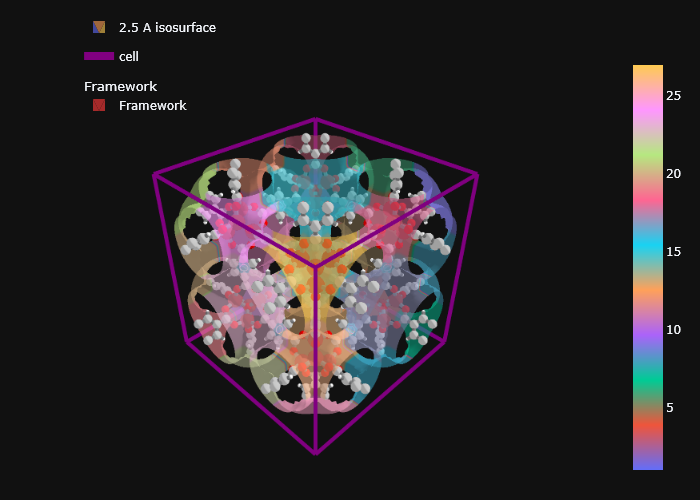

In [6]:
fig = go.Figure(data=[isosurface_trace, cell_trace, *frame_trace]).update(layout=mgr.dark_layout)
fig.show(renderer='png')

As you might have already noticed, if you hover over the surface, the region number is displayed as pop up.

### Tips and tricks #1
As before you can use the `stylize` argument to add some fany lighting effects into the isosurface and frame mesh traces. Please refer to the earlier tuturial for example code.

## Where to go next

You can go in a couple of different directions from here. The tutorial on Applying PBC and the tutorial on the Region Adjacency Graph (pore graph) are both accessible to you now. 